In [11]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import japanize_matplotlib

In [12]:
candidate_paths = [
    Path.cwd() / 'data/processed/regional_enrollment_rates.csv',
    Path.cwd().parent / 'data/processed/regional_enrollment_rates.csv',
]
data_path = next((path for path in candidate_paths if path.exists()), None)
if data_path is None:
    raise FileNotFoundError('regional_enrollment_rates.csv が見つかりません。')
df_rates = pd.read_csv(data_path)
df_rates.head()

,year,origin,kanto_enrollment_ratio,kansai_enrollment_ratio,chukyo_enrollment_ratio
0,1975,三重県,0.248410,0.259928,0.420664
1,1975,京都府,0.085865,0.824847,0.031733
2,1975,佐賀県,0.263271,0.073949,0.016569
3,1975,兵庫県,0.107379,0.779213,0.027180
4,1975,北海道,0.354576,0.029430,0.011546


In [13]:
# 1年×1出身地が1行で、対象年と出身地が揃っていることを確認する
assert not df_rates.duplicated(['year', 'origin']).any()
assert df_rates['year'].nunique() == 51
assert df_rates['origin'].nunique() == 47
assert df_rates.shape[0] == 51 * 47
df_rates.describe(include='all')

,year,origin,kanto_enrollment_ratio,kansai_enrollment_ratio,chukyo_enrollment_ratio
count,2397.000000,2397,2397.000000,2397.000000,2397.000000
unique,NaN,47,NaN,NaN,NaN
top,NaN,三重県,NaN,NaN,NaN
freq,NaN,51,NaN,NaN,NaN
mean,2000.000000,NaN,0.333283,0.190871,0.064281
std,14.722673,NaN,0.285721,0.255175,0.150019
min,1975.000000,NaN,0.031776,0.005805,0.001246
25%,1987.000000,NaN,0.126442,0.022538,0.007746
50%,2000.000000,NaN,0.211595,0.072010,0.016736
75%,2013.000000,NaN,0.471637,0.235602,0.038773


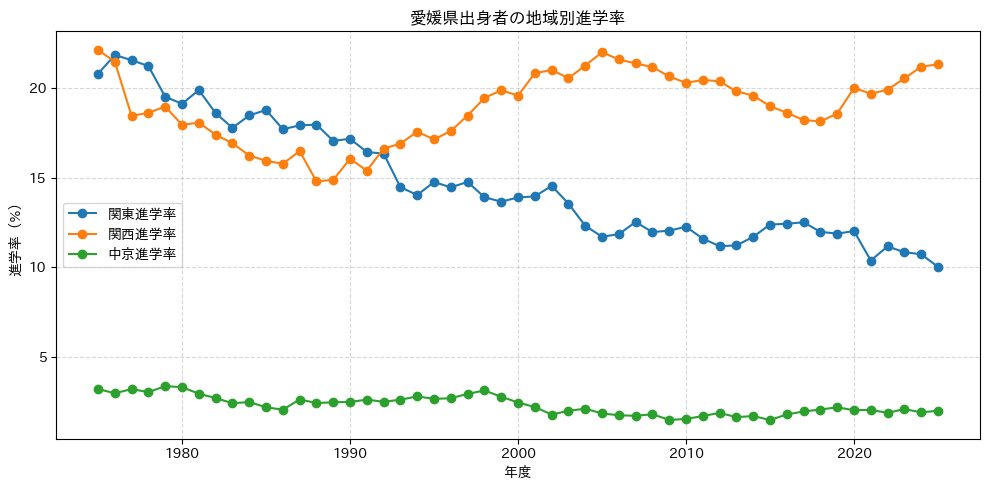

In [16]:
origin = '愛媛県'
origin_rates = (
    df_rates[df_rates['origin'] == origin]
    .sort_values('year')
)

plt.figure(figsize=(10, 5))
for column, label in [
    ('kanto_enrollment_ratio', '関東進学率'),
    ('kansai_enrollment_ratio', '関西進学率'),
    ('chukyo_enrollment_ratio', '中京進学率'),
]:
    plt.plot(origin_rates['year'], origin_rates[column] * 100, marker='o', label=label)
plt.title(f'{origin}出身者の地域別進学率')
plt.xlabel('年度')
plt.ylabel('進学率（%）')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
# 各年度の都道府県別進学率を比較する
year = 2025
year_rates = df_rates[df_rates['year'] == year].sort_values(
    'kanto_enrollment_ratio', ascending=False
)
year_rates[['origin', 'kanto_enrollment_ratio', 'kansai_enrollment_ratio', 'chukyo_enrollment_ratio']].head(10)

,origin,kanto_enrollment_ratio,kansai_enrollment_ratio,chukyo_enrollment_ratio
2357,埼玉県,0.954234,0.008719,0.002228
2382,神奈川県,0.953112,0.009717,0.002522
2355,千葉県,0.951140,0.011194,0.005422
2376,東京都,0.947395,0.012816,0.002405
2387,群馬県,0.865118,0.024247,0.004398
2388,茨城県,0.860238,0.033929,0.011964
2377,栃木県,0.849568,0.016500,0.004210
2366,山梨県,0.545357,0.075566,0.045625
2385,福島県,0.512209,0.014055,0.003691
2390,長野県,0.494691,0.058035,0.086486
